AI assistance: ChatGPT was used as a sparring partner and to assist in generating code for multi-plot and overlay visualizations. The generated code was reviewed and adapted by the authors.

In [ ]:
import requests
from IPython.core.display import HTML
HTML(f"""
<style>
</style>
""")

# PCA for shape generation
<article class="message is-info">
  <div class="message-body">
  
The assignment applies PCA to generate face shapes. The objective is to explore the relationship between points in the latent space and their corresponding representations in the data space.

  
  </div>
</article>

<article class="message is-success">
  <div class="message-header">Refresh</div>
  <div class="message-body">
  
  The eigenvalue $\lambda_i$ is equal to the variance $\sigma_i^2$ along the direction of its eigenvector $v_i$. This equivalence allows us to use $\lambda_i$ and $\sigma_i^2$ interchangeably. Furthermore observe that the variance is given by $\sigma^2$ and hence the  standard deviation is given by $\sigma$ (standard deviation).
That is:

$$\lambda_i = \sigma_i^2$$
and therefore:

$$\sigma_i = \sqrt{\lambda_i}$$

  
  </div>
</article>

<div style="float: none; width: 100%; justify-content: start" class="block is-clearfix">


<article class="message">
    <div class="message-body">
        <strong>Overview of mandatory tasks</strong>
        <ul style="list-style: none;">
            <li>
            <a href="#prep">Task 1: Data inspection</a>
            </li>
            <li>
            <a href="#get_pca">Task 2: Evaluate Principal compoenets</a>
            </li>
            <li>
            <a href="#gen">Task 3: Base face</a>
            </li>
            <li>
            <a href="#gen_reflect">Task 4: Base face reflections </a>
            </li>
            <li>
            <a href="#c">Task 5: Investigate variations in latent space</a>
            </li>
            <li>
            <a href="#interpolate">Task 6: Interpolation between two faces</a>
            </li>
            <li>
            <a href="#reflect">Task 7: Reflection</a>
            </li>
            <li>
            <a href="#correlation_eigen">Task 8: Eigenvalues and eigenvectors of correlat…</a>
            </li>
            <li>
            <a href="#Dimensionality_red">Task 9: Out of distribution generation</a>
            </li>
        </ul>
    </div>
</article>



</div>

# Part 1
## Data
## Task 1: Data inspection

1. Run the cell below to load libraries, the data and to  visualize the first 6 sample face shapes.



</div></article>



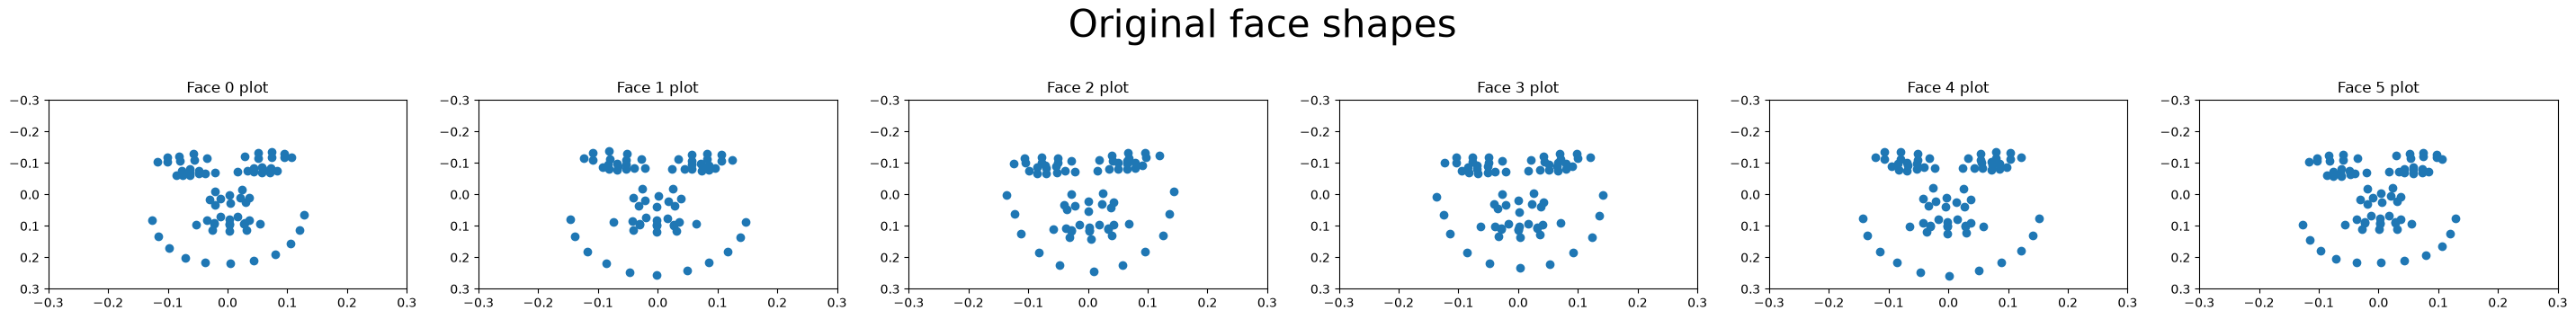

In [138]:
# TASK 1
import matplotlib.pyplot as plt
import numpy as np
import scipy
from pca_utils import *
import os
from glob import glob
import warnings
warnings.filterwarnings('ignore')
path = './db/'
shapes, _ = face_shape_data(path)

plot_many_faces(shapes[:6],"Original face shapes");

## PCA implementation

## Task 2: Get principal compontents


1. Complete the `get_principal_components`
 function so that it returns all principal components `comp`
, eigenvalues `val`
 and mean vector `mu`
, given the dataset `shapes`
.
2. Use the `get_principal_components`
 function to calculate the principal components (`comp`
) for the face dataset.
3. Implement the function `transform_to_latent_space`
  according to the comments in the cell below using  $\mathbf{a} = \mathbf{\Phi_k}^\top(\mathbf{x}-\mathbf{\mu})$ .
4. Implement the function `transform_from_latent_space`
  according to the comments in the cell below using $x  = \mathbf{\Phi_k} \mathbf{a} + \mathbf{\mu}$ .
5. Run the cell below to map $6$ face shapes to the latent space and back to the original data space. The `plot_many_faces`
 function is used to display both the original and the restored face shapes.
6. Visually inspect the figures and describe the reconstruction error.



</div></article>



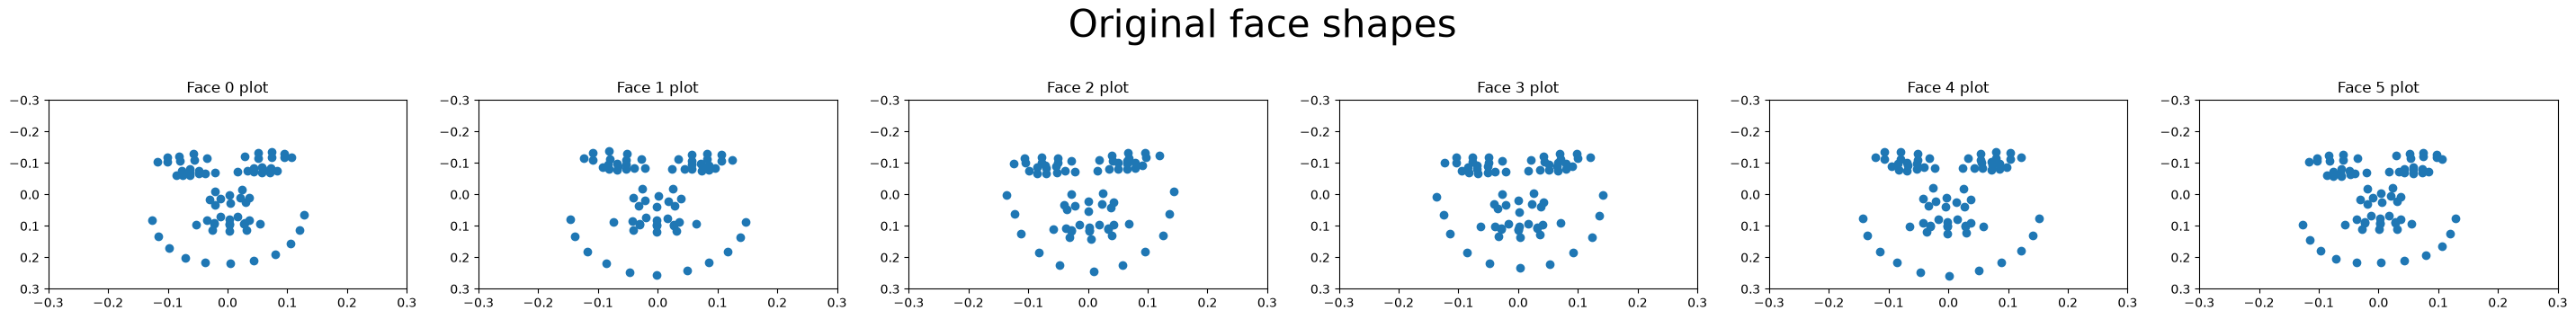

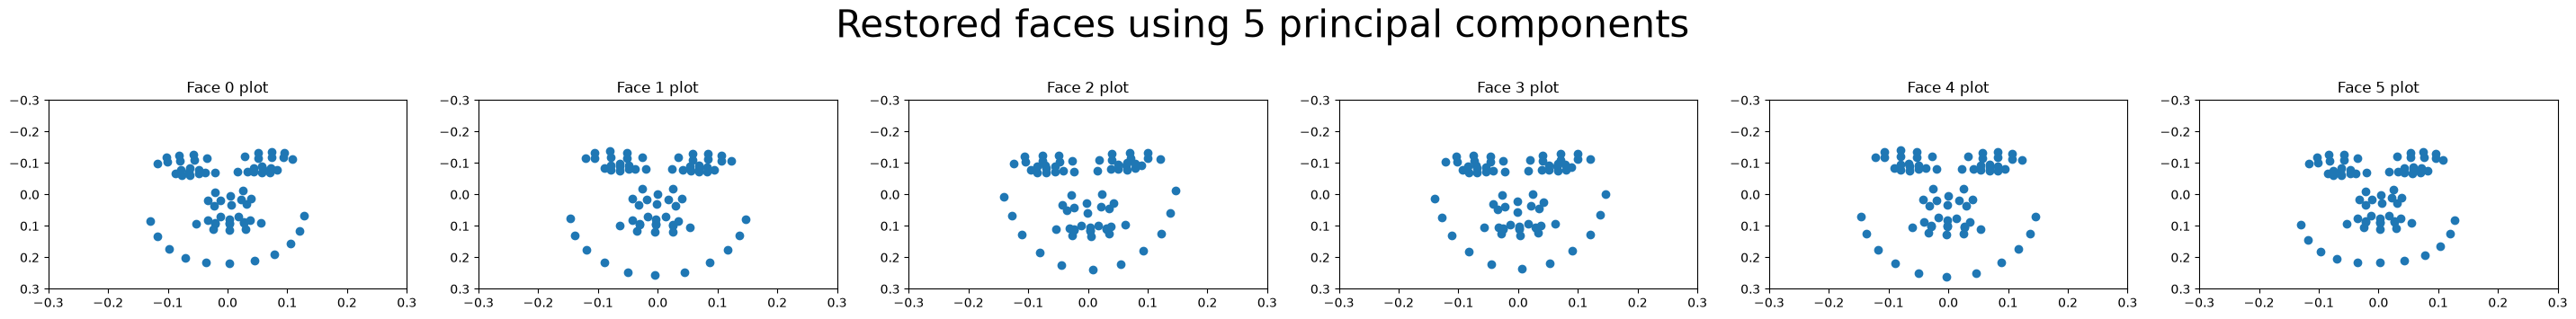

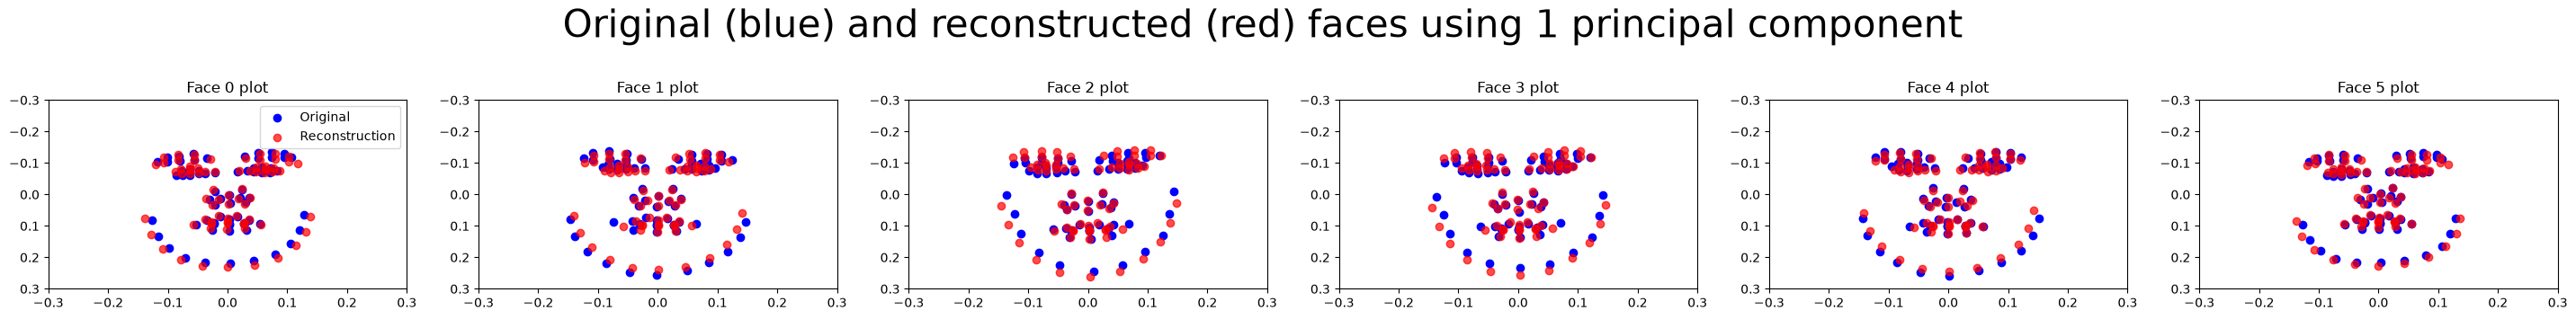

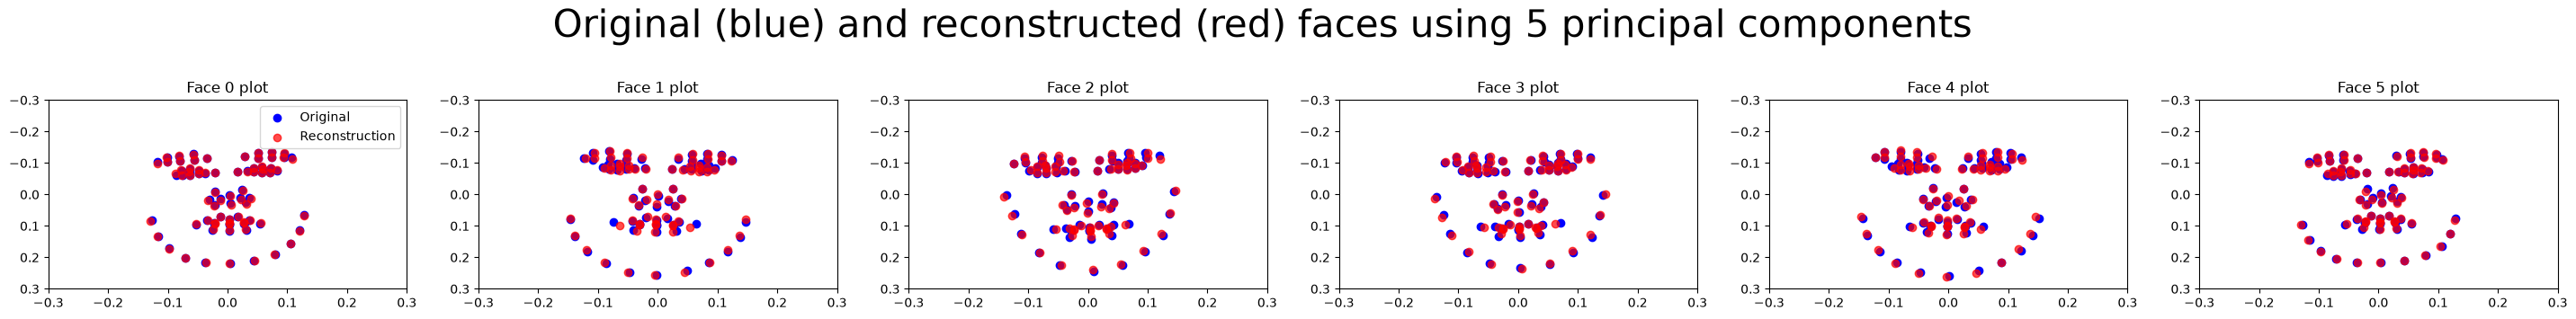

In [139]:
from os import error

# TASK 2.1: Complete the `get_principal_components` function

def get_principal_components(X):
    """Calculates principle components for X.

    Args:
        X: The dataset. An NxD array were N are the number of samples and D are
        the number of features.

    Returns:
        Tuple (components, eigenvalues, mu) where components is a DxD matrix of
        principle components, eigenvalues is a D-element vector of
        corresponding eigenvalues, and mu is a D-element array containing the mean
        vector.
    """
    mu = np.mean(X, axis=0) # Calculate the mean of the dataset
    X_centered = X - mu # Center the data
    cov_matrix = np.cov(X_centered.T) # Calculate the covariance matrix
    eigenvalues, eigenvectors = np.linalg.eig(cov_matrix) # Calculate the eigenvalues and eigenvectors of the covariance matrix
    idx = np.argsort(eigenvalues)[::-1] # Sort the eigenvalues and eigenvectors in descending order
    eigenvalues = eigenvalues[idx]
    eigenvectors = eigenvectors[:, idx]
    return eigenvectors, eigenvalues, mu


# TASK 2.2: Use 'get_principal_components'
comp, val, mu = get_principal_components(shapes)

cumulative_variance = np.cumsum(val) / np.sum(val)

n_components = 5


# TASK 2.3: Implement 'transform_to_latent_space'
def transform_to_latent_space(X, principle_components, mu):
    """Transforms X to an k-dimensional space where k is the number of
    principle_components.

    Args:
        X: The dataset. An NxD array were N are the number of samples and D are
        the number of features.
        principle_components: An Dxk matrix containing the principle
        components.
        mu: A D-element array containing the mean vector.

    Returns:
        A Nxk array describing the transformed data.
    """
    return np.dot(X - mu, principle_components)
    
# TASK 2.4: Implement 'transform_from_latent_space'
def transform_from_latent_space(v, principle_components, mu):
    """Reverses the dimensionality reduction of v, a Nxk matrix where
    k is the number of principle components. The result is a NxM matrix.

    Args:
        v: The transformed dataset with size Nxk.
        principle_components: An Dxk matrix containing the principle
        components.
        mu: A Mx1 matrix containing the mean vector.

    Returns:
        An NxD array reconstruction of the original feature vectors X.
    """
    return np.dot(v, principle_components.T) + mu

# TASK 2.5: Use the functions to transform and reconstruct the data    
used = comp[:, :n_components]

# transforming and reconstructing the 6 first faces in the dataset
plot_many_faces(shapes[:6],"Original face shapes")
transformed = transform_to_latent_space(shapes[:6], used, mu)
restored = transform_from_latent_space(transformed, used, mu)
plot_many_faces(restored,"Restored faces using 5 principal components")


### ------ CUSTOM OVERLAY PLOTS FOR ANSWERING TASK 2.6 REFLECTIONS ------

def plot_overlay(original_faces, reconstructed_faces, n_components):
    """Plot original and reconstructed faces on top of each other."""
    n_faces = len(original_faces)
    row = 6 if n_faces > 6 else n_faces
    n_rows = int(1 + n_faces // 6)

    # Use the same figure-size formula and subplot layout as plot_many_faces
    plt.figure(figsize=(int(6*n_faces), int(1+n_faces//7)*6))
    plt.suptitle(
        "Original (blue) and reconstructed (red) faces using %d principal component%s"
        % (n_components, "" if n_components == 1 else "s"),
        fontsize=30,
        y=1.05,
    )

    axes = []
    for pos, (original, reconstruction) in enumerate(
        zip(original_faces, reconstructed_faces)
    ):
        ax = plt.subplot(n_rows, row, pos + 1)
        axes.append(ax)
        original_points = original.reshape(-1, 2)
        reconstruction_points = reconstruction.reshape(-1, 2)

        ax.scatter(original_points[:, 0], original_points[:, 1],
                   color="blue",
                   label="Original" if pos == 0 else None)
        ax.scatter(reconstruction_points[:, 0], reconstruction_points[:, 1],
                   color="red", alpha=0.7,
                   label="Reconstruction" if pos == 0 else None)

        ax.set_title("Face %d plot" % pos)
        ax.set_ylim((-0.3, 0.3))
        ax.set_xlim((-0.3, 0.3))
        ax.invert_yaxis()

    axes[0].legend(loc="upper right")
    plt.show()

# Overlay with 1 principal component
used_1 = comp[:, :1]
transformed_1 = transform_to_latent_space(shapes[:6], used_1, mu)
restored_1 = transform_from_latent_space(transformed_1, used_1, mu)
plot_overlay(shapes[:6], restored_1, 1)

# Overlay with 5 principal components
plot_overlay(shapes[:6], restored, 5)


In [114]:
# TASK 2.6: **Reflections** – Write your reflections on the results of the PCA analysis and the reconstruction of the face shapes.

### As the number of principal components increases, the reconstructed faces become more similar to the original faces. 
### With only 1 principal component, we can see that the reconstructed faces (red) on top of the originals (blue) have deviations in almost each point. We can see, that there is an information loss, when discarding all other principal components
### With 5 principal components, the difference between points in the reconstruction (red) and original (blue) is less clear, indicating a better preservation of the original facial features. 

## Task 3: Evaluate Principal compoenets

1. How many components are needed to retain $50\%$, $60\%$, $80\%$, $95\%$ of the total variation?
2. Seting $k=5$ components. How much of the total variance is retained?
3. Visually inspect the figures and describe the reconstruction error.




/opt/anaconda3/envs/iml/lib/python3.11/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


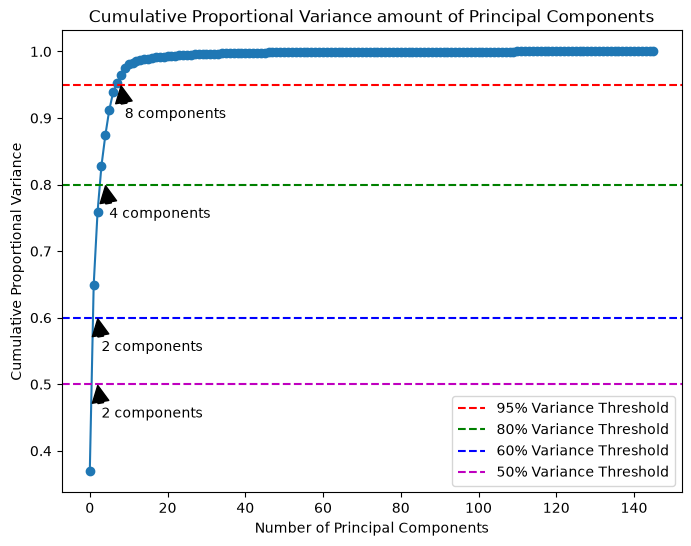

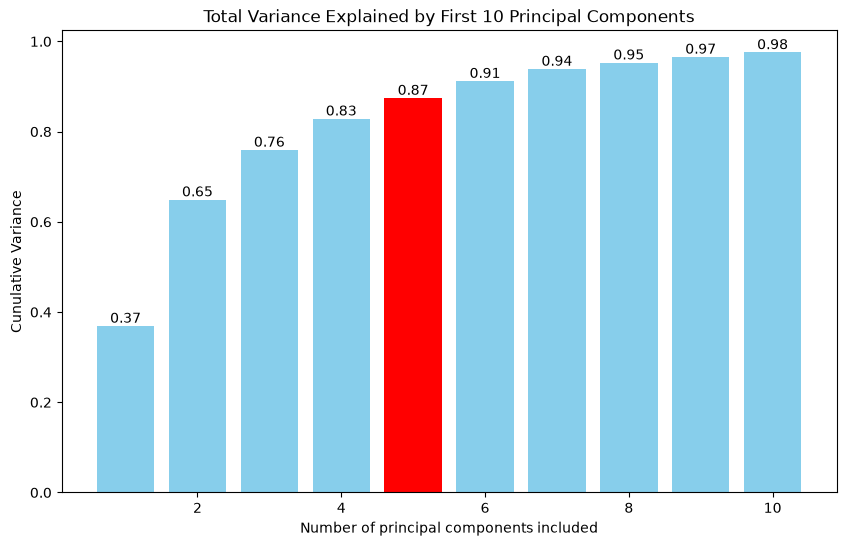

In [115]:
### CODE TO PLOT THE CUMULATIVE PROPORTIONAL VARIANCE AND TOTAL VARIANCE EXPLAINED BY PRINCIPAL COMPONENTS – REFLECTIONS BELOW PLOTs

### PLOT the cumulative proportional variance
plt.figure(figsize=(8, 6))
plt.plot(cumulative_variance, marker='o', linestyle='-')
plt.title('Cumulative Proportional Variance amount of Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Proportional Variance')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Variance Threshold')
plt.axhline(y=0.80, color='g', linestyle='--', label='80% Variance Threshold')
plt.axhline(y=0.60, color='b', linestyle='--', label='60% Variance Threshold')
plt.axhline(y=0.50, color='m', linestyle='--', label='50% Variance Threshold')
plt.legend()
### Show the value at 50, 60, 80, 95 variance threshold
num_components_50 = np.argmax(cumulative_variance >= 0.50) + 1
num_components_60 = np.argmax(cumulative_variance >= 0.60) + 1
num_components_80 = np.argmax(cumulative_variance >= 0.80) + 1
num_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

### Annotations for the number of components at each threshold
plt.annotate(f'{num_components_50} components', xy=(num_components_50, 0.50), xytext=(num_components_50 + 1, 0.45),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'{num_components_60} components', xy=(num_components_60, 0.60), xytext=(num_components_60 + 1, 0.55),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'{num_components_80} components', xy=(num_components_80, 0.80), xytext=(num_components_80 + 1, 0.75),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'{num_components_95} components', xy=(num_components_95, 0.95), xytext=(num_components_95 + 1, 0.9),
             arrowprops=dict(facecolor='black', shrink=0.05))


plt.figure(figsize=(10, 6))
total_variances = [cumulative_variance[i].real for i in range(10)]
plt.bar(range(1, 11), total_variances, color=['skyblue'] * 4 + ['red'] + ['skyblue'] * 5)
plt.title('Total Variance Explained by First 10 Principal Components')
plt.ylabel('Cunulative Variance')
plt.xlabel('Number of principal components included')
for i, variance in enumerate(total_variances):
    plt.annotate(f'{variance:.2f}', xy=(i + 1, variance), ha='center', va='bottom')
plt.show()


In [140]:
# TASK 3.1. How many components are needed to retain $50\%$, $60\%$, $80\%$, $95\%$ of the total variation?

### As denoted in plot above, the number of components needed to retain 50%, 60%, 80%, and 95% of the total variation are as follows:
### 50%: 2 components
### 60%: 2 components
### 80%: 4 components
### 95%: 8 components

# TASK 3.2. Seting $k=5$ components. How much of the total variance is retained?

### As denoted in plot above, with 5 components, we can retain approximately 87% of the total variance.

# TASK 3.3. Visually inspect the figures and describe the reconstruction error.

### To us atleast, it seems that the postion of the eyes are relatively stable, while the shift (between red and blue in the overlayed plot) mainly occurs in mouth, jaw, and eyebrow areas.

# Part 2
## Using PCA for shape generation
The principal components can be used to generate new samples $\mathbf{x}$ in data space by transforming a point in latent space according to 
$$\mathbf{x} = \Phi_{k} a + \mu$$
 where $\Phi_{k}$ is the matrix of k eigenvectors, $\mathbf{a}\in\mathbb{R}^{k}$ is a vector in latent space, and $\mu\in\mathbb{R}^{D}$ is the mean vector of the original data features in  the data space.

$$

{\Phi_k} = \begin{bmatrix} | & | & & | \\ {v}_1 & {v}_2 & \cdots & {v}_k \\ | & | & & | \end{bmatrix}

$$
The variance of the data in a given direction can be used to constrain the values of the elements of the vector $\mathbf{a}$ in latent space, assuming that the data follows a (multivariate) normal distribution. In a multivariate normal distribution each direction $v_i$ is also normally distributed. Each element $a_i$ can be constrained to be within the observed variance in direction $v_i$. The variance $\sigma_i^2$ in the direction of $v_i$ is given by the eigenvalue $\lambda_i$, so the standard deviation is  $\sigma_i = \sqrt{\lambda_i}$.
In a 1D normal distribution (with mean $\mu$ and standard deviation $\sigma$), the area under the Gaussian curve between $\pm 3\sigma$ contains $99.7\%$ of the data (see [Figure 1](#normal) ). Thus, constraining each element $a_i$ to the interval $[-3\sigma_i, 3\sigma_i]$ will cover $99.7\%$ of the variance in the direction of $v_i$.
<div class="has-text-centered">
<figure class="image is-inline-block" id="normal">

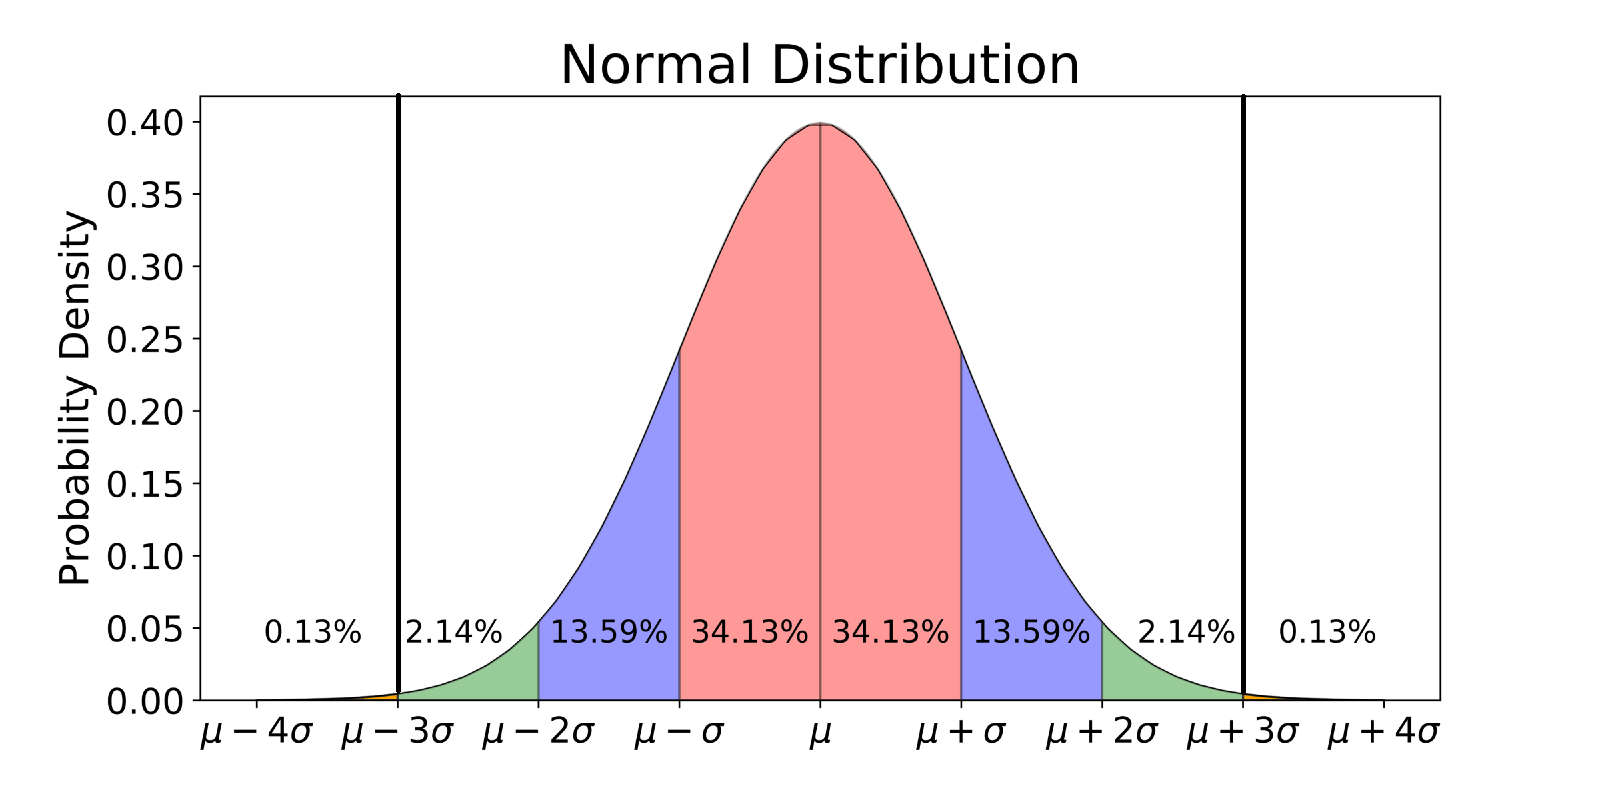

<figcaption class="figure-caption has-text-centered">Figure 1: Illustration of a normal distribution. The vertical lines mark the region covering $99.7\%$ of the variance. The shaded regions indicate the
area of the distribution covered by 1, 2, 3, and 4, standard deviations
($\sigma$) respectively.
</figcaption>
</figure>
</div>



## Task 4: Base face


1. **Generate vectors:** run the cell below to create the zero vector in latent space, i.e. $\mathbf{a} = [0, 0, \dots, 0]\in\mathbb{R}^5$.
2. **Shape generation:** use $\mathbf{x} = \mathbf{\Phi} \mathbf{a} + \mathbf{\mu}$ to generate a face (vector in real space) from the vector $\mathbf{a}$. Use the `plot_face`
 function to visualise the generated face.
3. Change the elements of $\mathbf{a}$ to the values below, where $\lambda_i$ is the i-th eigenvalue and plot the resulting shapes for each modification:
    - $\mathbf{a} = [\sqrt{\lambda_1},0, 0, 0, 0]$ $\in\mathbb{R}^5$?
    - $\mathbf{a} = [0,-3\sqrt{\lambda_2}, 0, 0, 0]$ $\in\mathbb{R}^5$?





</div></article>

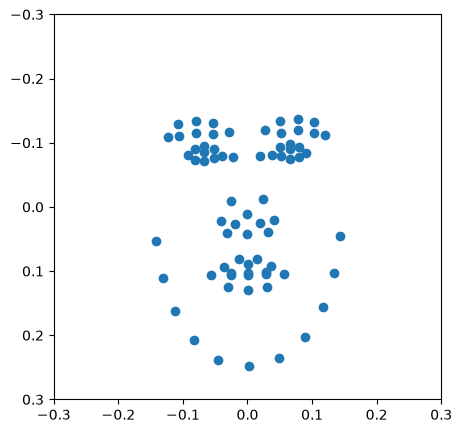

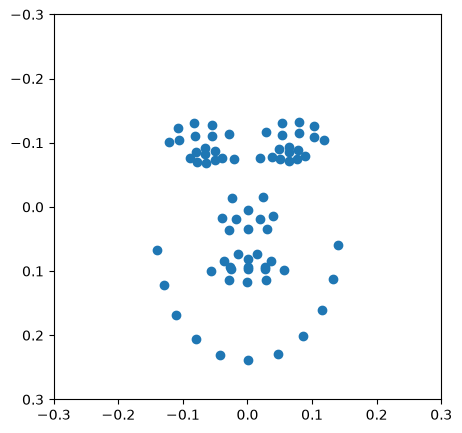

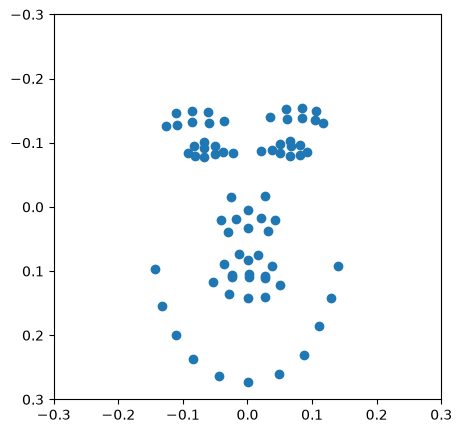

In [116]:
# TASK 4.1: Generate Vectors

a = np.array([0,0,0,0,0])

# TASK 4.2. Shape Generation
plot_face(generated_mean_face)

# TASK 4.3. New PC Variations

a_1 = np.array([np.sqrt(val[0]), 0, 0, 0, 0])
generated_face_1 = transform_from_latent_space(a_1, used, mu)
plot_face(generated_face_1)

a_2 = np.array([0, -3*np.sqrt(val[1]), 0, 0, 0])
generated_face_2 = transform_from_latent_space(a_2, used, mu)
plot_face(generated_face_2)

## Task 5: Base face reflections


1. Use $\mathbf{x} = \Phi_{k} a + \mu$ to explain what the vector $a \in R^5$ represents if    - $\mathbf{a}= [0,0,0,0,0]$?
    - $\mathbf{a} = [\sqrt{\lambda_1},0, 0, 0, 0]$?
    - $\mathbf{a} = [0,-3\sqrt{\lambda_2}, 0, 0, 0]$?


2. Describe what face is generated and why.



</div></article>



In [117]:
# Write your reflections here

# TASK 5.1 & 5.2

### When $\mathbf{a} = [0,0,0,0,0]$, the generated face corresponds to the mean face of the dataset. 
### This is because all principal components are weighted by zero, resulting in no deviation from the mean.
### In math terms, $\mathbf{x} = \Phi_{k} a + \mu$ simplifies to $\mathbf{x} = \mu$, which is exactly the mean face.

### When $\mathbf{a} = [\sqrt{\lambda_1},0, 0, 0, 0]$, the generated face represents a variation in the direction of the first principal component.
### When $\mathbf{a} = [0,-3\sqrt{\lambda_2}, 0, 0, 0]$, the generated face represents a variation in the direction of the second principal component.
### In math terms, $\mathbf{x} = \Phi_{k} a + \mu$ simplifies to $\mathbf{x} = \Phi_{k} a + \mu$, which represents a variation in the direction of the principal components.



# Investigating principal components

## Task 6: Investigate variations in latent space


1. **Varying the 1st component:** Let $\mathbf{a} \in \mathbb{R^5}$ be a vector in the latent space. Generate 5 different vectors where only the first element, $a_1$, varies, while the remaining elements, $a_2, a_3, a_4, a_5$, are set to 0. Use `np.linspace`
 to generate 5 evenly spaced values for $a_1$ in the interval $[-3\sigma_1, 3\sigma_1]$. For each value of $a_1$, generate a corresponding face and display all 5 faces in a plot.

2. **More components:** Do the same for each of the remaining four components, i.e. $a_2$-$a_5$ leaving the others as 0.

3. **Component analysis:** Describe how each principal component changes the face shape (for example, the first component may change the length of the face).




</div></article>



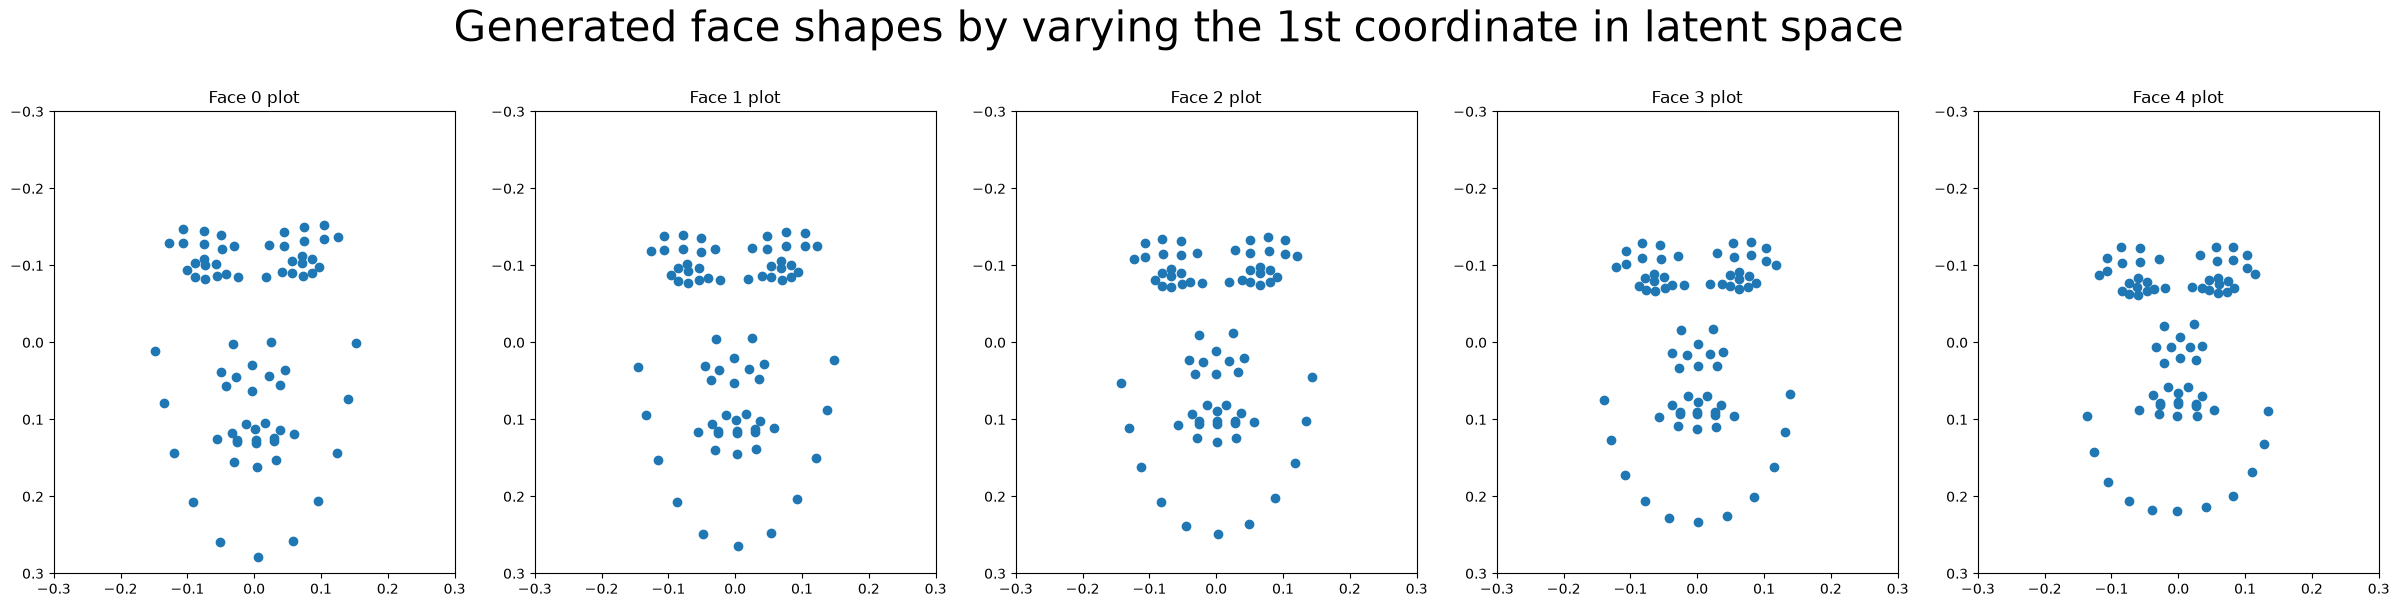

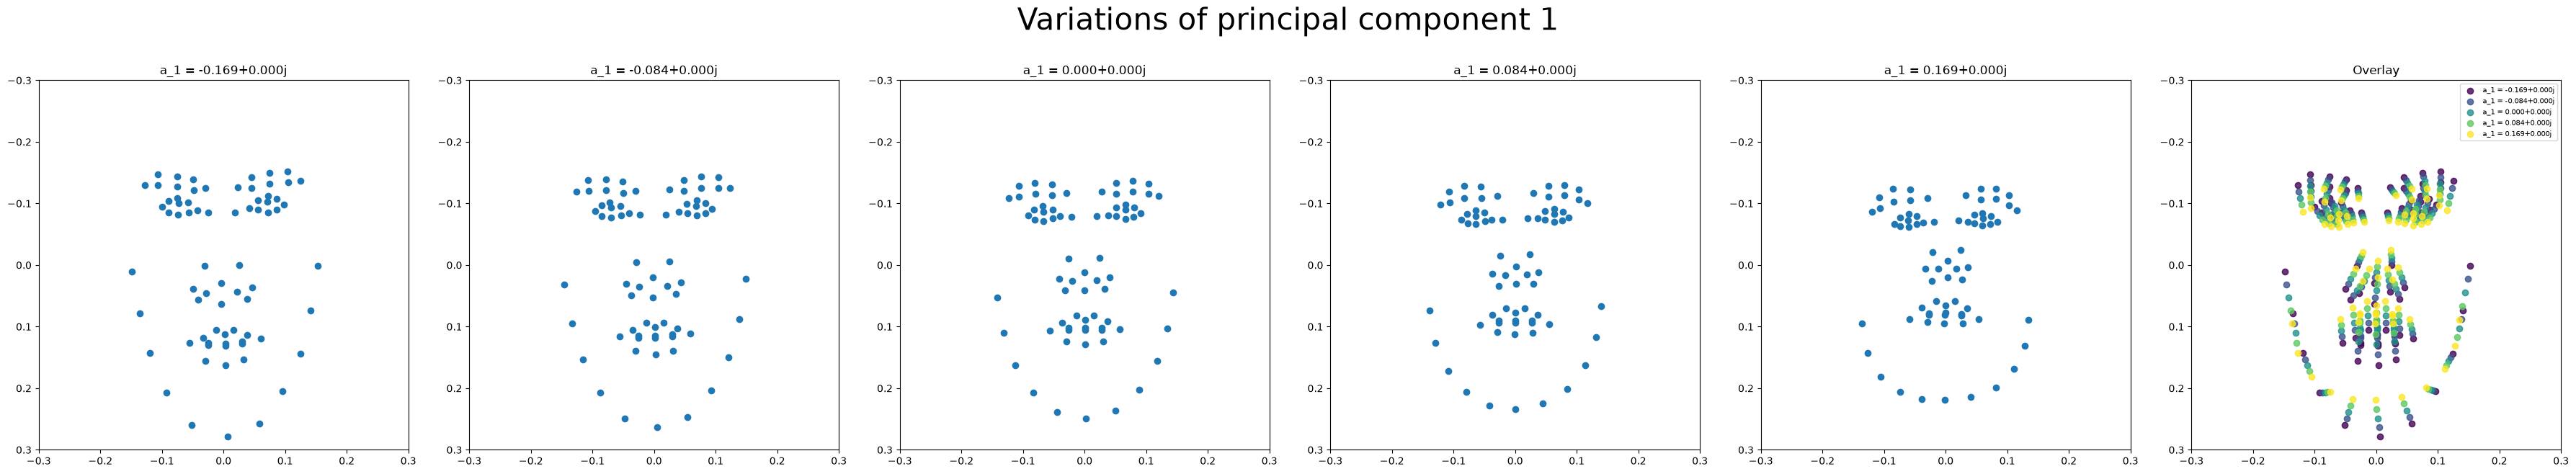

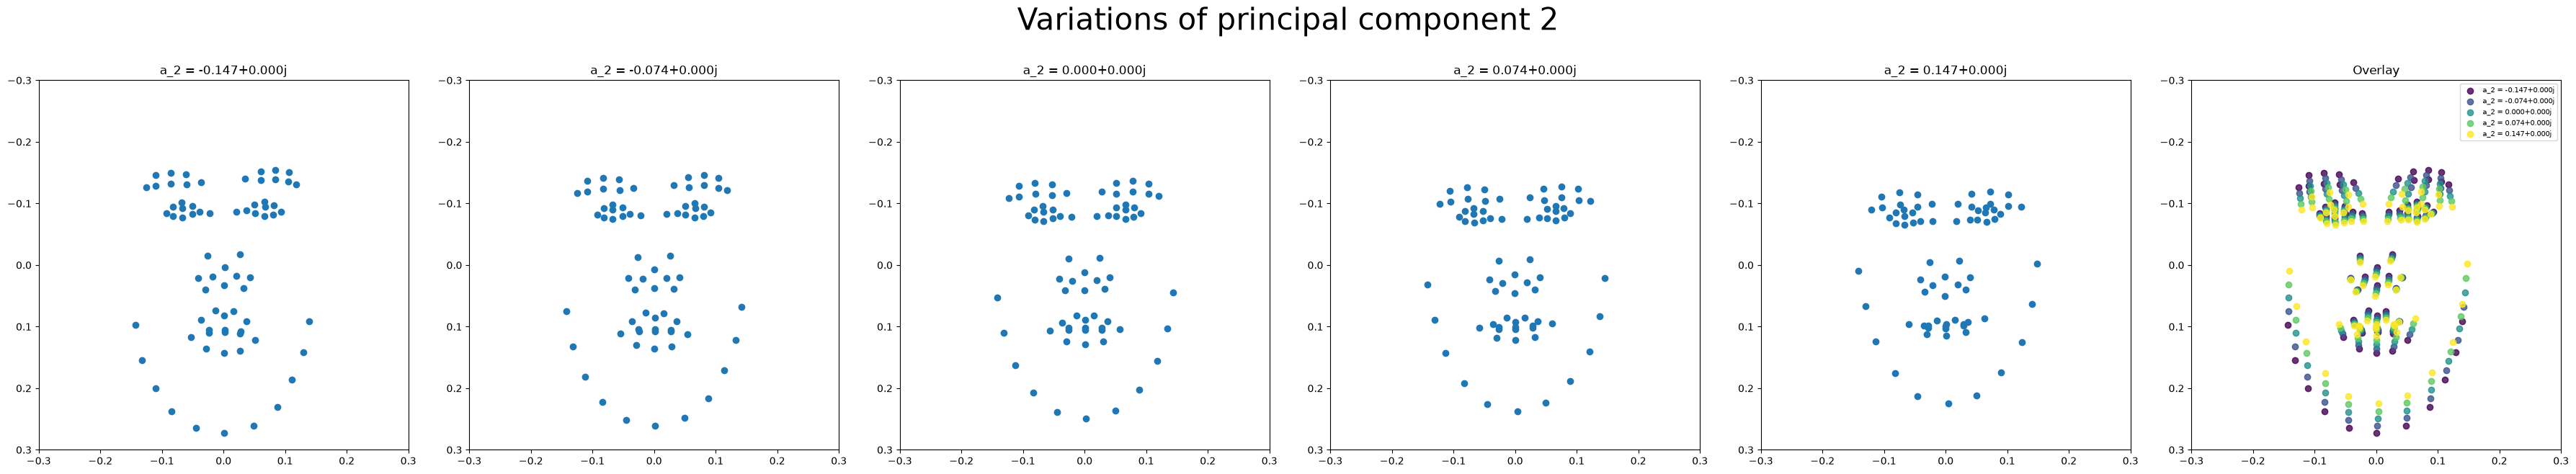

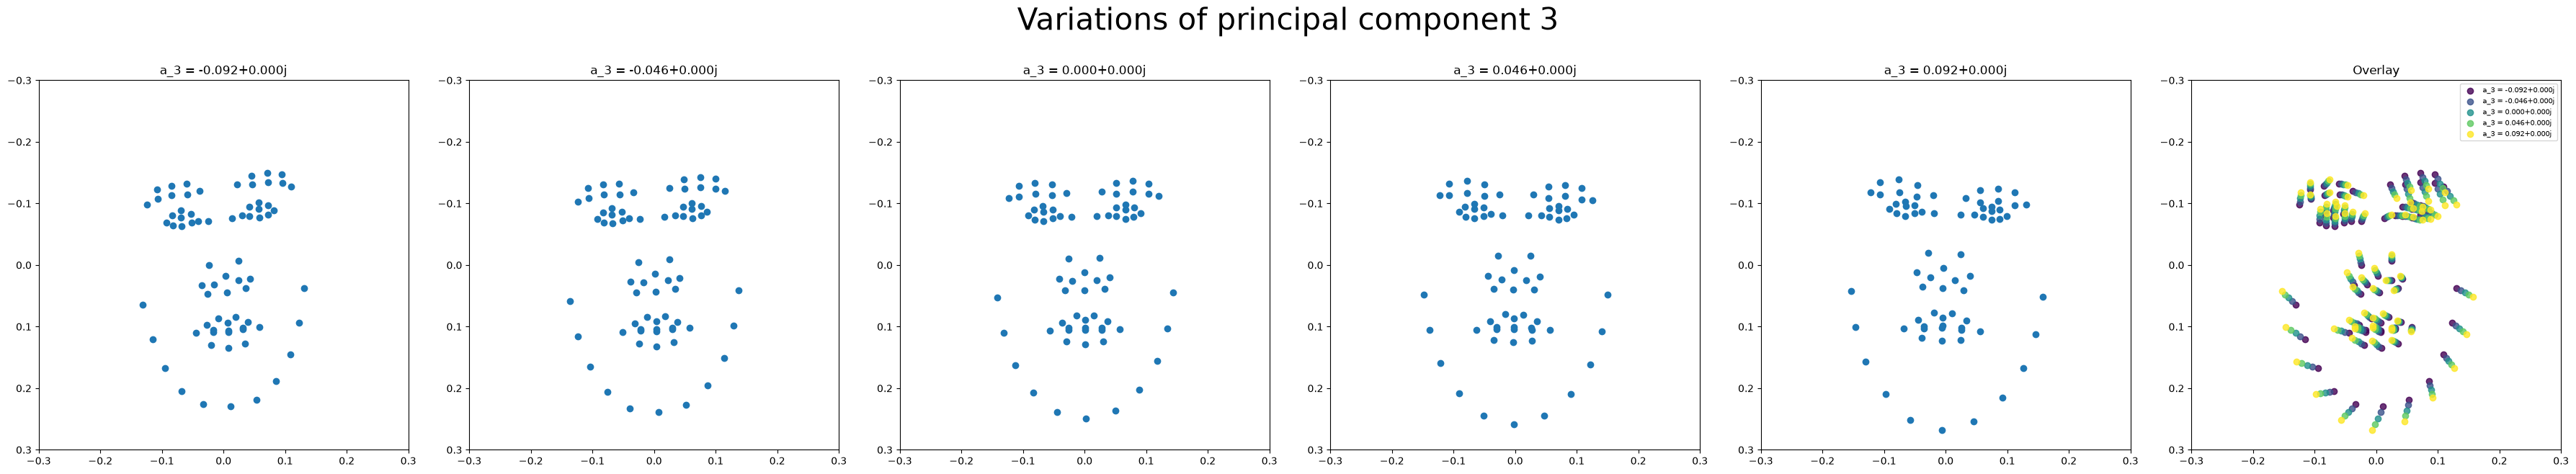

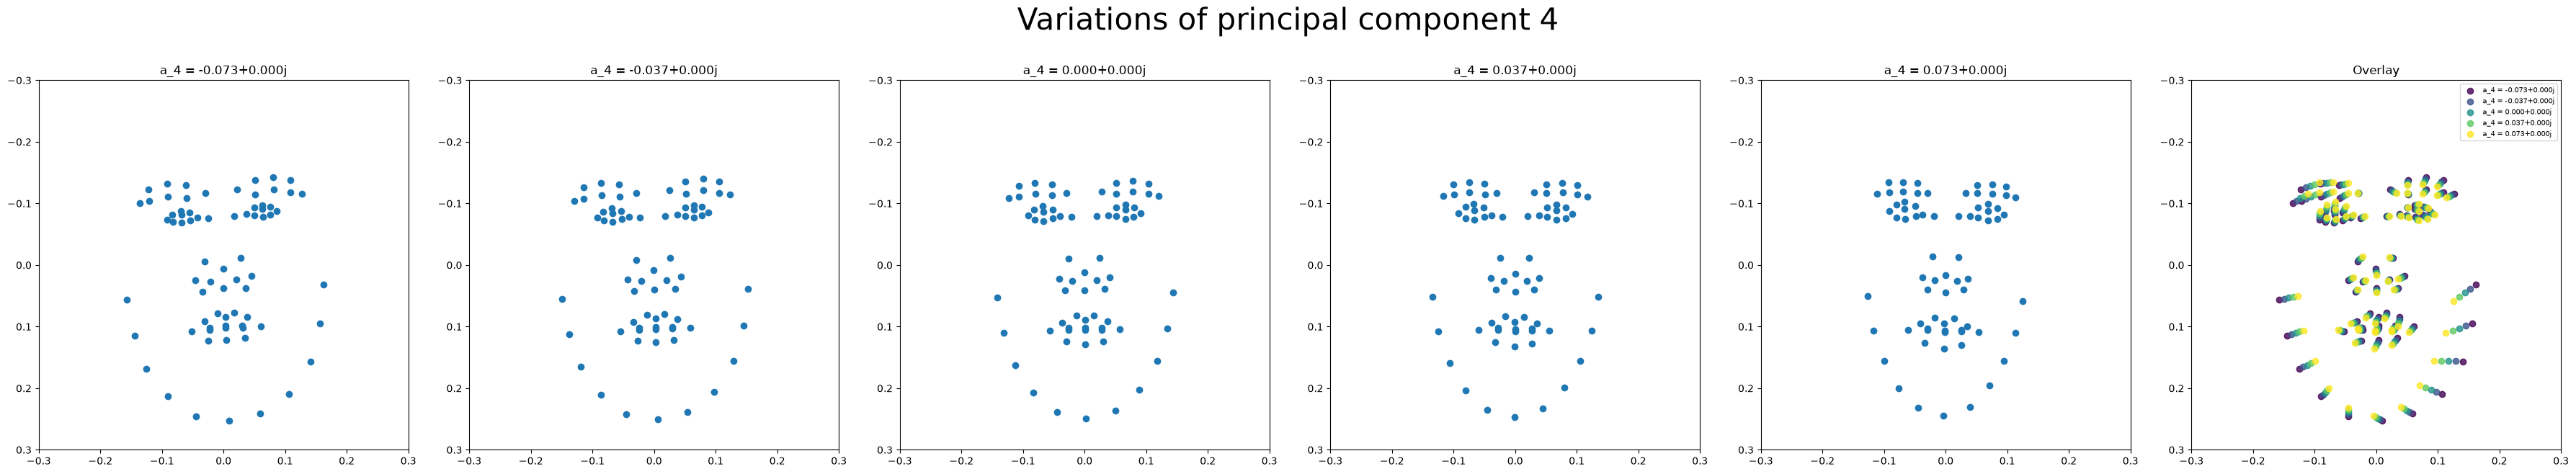

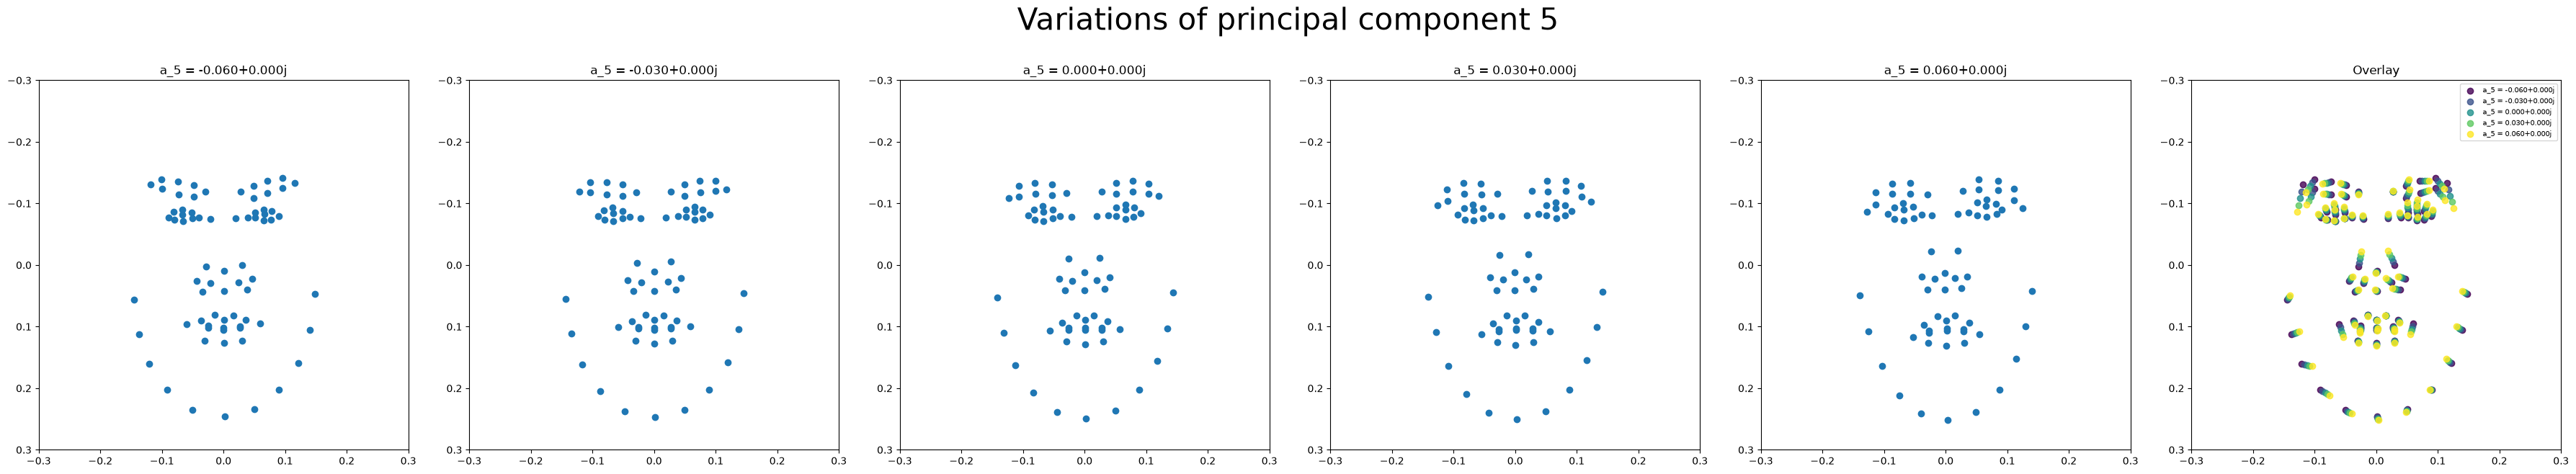

In [141]:
# TASK 6.1: Varying the 1st component
std_1 = np.sqrt(val[0]) # std/eigvalue for the first PC
a = np.zeros(5)
gen_shapes = []
used = comp[:, :5]
for i in range(5):
    a[0] = np.linspace(-3*std_1, 3*std_1, num=5)[i]
    x = np.dot(used, a) + mu
    gen_shapes.append(x)

plot_many_faces(gen_shapes,"Generated face shapes by varying the 1st coordinate in latent space")

# TASK 6.2. More components!

###---- CUSTOM IMPLEMENTATION FOR OVERLAYING FACES GENERATED BY VARYING PRINCIPAL COMPONENTS ----

def generate_faces_by_varying_component(component_index, std_dev, num_faces=5):
    values = np.linspace(-3*std_dev, 3*std_dev, num=num_faces)
    used = comp[:, :5]
    gen_shapes = []
    for value in values:
        a = np.zeros(5)
        a[component_index] = value
        x = np.dot(used, a) + mu
        gen_shapes.append(x)
    return values, gen_shapes

values_1, gen_shapes_1 = generate_faces_by_varying_component(0, np.sqrt(val[0]))
values_2, gen_shapes_2 = generate_faces_by_varying_component(1, np.sqrt(val[1]))
values_3, gen_shapes_3 = generate_faces_by_varying_component(2, np.sqrt(val[2]))
values_4, gen_shapes_4 = generate_faces_by_varying_component(3, np.sqrt(val[3]))
values_5, gen_shapes_5 = generate_faces_by_varying_component(4, np.sqrt(val[4]))

def plot_component_variations(values, generated_faces, component_index):
    """Plot five variations side-by-side, matching plot_many_faces."""
    n_faces = len(generated_faces)
    figure = plt.figure(figsize=(int(6*(n_faces + 1)), 6))
    figure.suptitle(
        f"Variations of principal component {component_index + 1}",
        fontsize=30,
        y=1.05,
    )

    for pos, (value, face) in enumerate(zip(values, generated_faces)):
        ax = plt.subplot(1, n_faces + 1, pos + 1)
        points = face.reshape(-1, 2)
        ax.scatter(points[:, 0], points[:, 1])
        ax.set_title(f"a_{component_index + 1} = {value:.3f}")
        ax.set_xlim((-0.3, 0.3))
        ax.set_ylim((-0.3, 0.3))
        ax.invert_yaxis()
        ax.set_aspect("equal")

    overlay_ax = plt.subplot(1, n_faces + 1, n_faces + 1)
    colors = plt.cm.viridis(np.linspace(0, 1, n_faces))
    for value, face, color in zip(values, generated_faces, colors):
        points = face.reshape(-1, 2)
        overlay_ax.scatter(
            points[:, 0],
            points[:, 1],
            color=color,
            alpha=0.8,
            label=f"a_{component_index + 1} = {value:.3f}",
        )
    overlay_ax.set_title("Overlay")
    overlay_ax.set_xlim((-0.3, 0.3))
    overlay_ax.set_ylim((-0.3, 0.3))
    overlay_ax.invert_yaxis()
    overlay_ax.set_aspect("equal")
    overlay_ax.legend(loc="best", fontsize=7)

    figure.tight_layout()
    plt.show()

def plot_component_variations_overlay(values, generated_faces, component_index):
    figure, ax = plt.subplots(figsize=(6, 6))
    colors = plt.cm.viridis(np.linspace(0, 1, len(generated_faces)))

    for value, face, color in zip(values, generated_faces, colors):
        points = face.reshape(-1, 2)
        ax.scatter(
            points[:, 0],
            points[:, 1],
            color=color,
            alpha=0.8,
            label=f"a_{component_index + 1} = {value:.3f}",
        )

    ax.set_title(
        f"Overlay of principal component {component_index + 1} variations",
        fontsize=16,
    )
    ax.set_xlim((-0.3, 0.3))
    ax.set_ylim((-0.3, 0.3))
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.legend(loc="best", fontsize=8)
    figure.tight_layout()
    return figure


component_variations = [
    (values_1, gen_shapes_1),
    (values_2, gen_shapes_2),
    (values_3, gen_shapes_3),
    (values_4, gen_shapes_4),
    (values_5, gen_shapes_5),
]

for i, (values, generated_faces) in enumerate(component_variations):
    plot_component_variations(values, generated_faces, i)


In [0]:
# TASK 6.3. **Component analysis:**

### The 1st principle component seems to control elongation/tilt of the face, making it appear longer or shorter, or the direction of where the person is looking.
### The 2nd principle component seems to control facial expression, the last generated index appears as a smiling person :-)
### The 3rd principle component seems to influence rotation of the face, one could interpret this as a confused look?
### The 4th principle component appears to control the size (cheeks) of the face's jawline. 
### The 5th principle component looks to affect whether a person looks angry (first picture) or sad (last picture). Specifically it seems the eyebrows move a lot

## Interpolating between shapes
The following example shows how to interpolate two vectors.


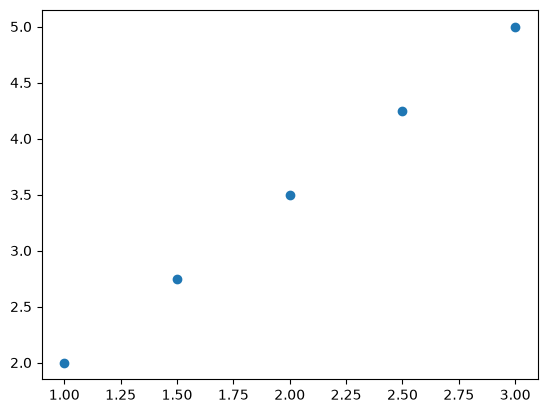

In [119]:
# #Template for doing interpolation between two (2D)- points 
d = np.linspace(np.array([1, 2]), np.array([3, 5]), num=5)
plt.scatter(d[:, 0], d[:, 1])

## Task 7: Interpolation between two faces


**Shape Interpolation:**
1. Select points $\mathbf{a}$ and $\mathbf{b}$ in latent space (paying attention to the Gaussian constraints) and generate the faces.
2. Use `np.linspace`
 to generate 6 evenly spaced points that interpolate between two vectors, $\mathbf{a}$ and $\mathbf{b}$, in the latent space. Plot the resulting faces.
3. Select $\mathbf{a}$ and $\mathbf{b}$ such that:    - $\mathbf{a}$ = $[-3\lambda_1,0,-3\lambda_3,0,0]$ and $\mathbf{b}$ = $[3\lambda_1,0,3\lambda_3,0,0]$.
    - $\mathbf{a}$ = $[0,5\lambda_2,0,0,0]$ and $\mathbf{b}$ = $[0,-5\lambda_2,0,0,0]$.
    - the generated shapes represent a smile.





</div></article>



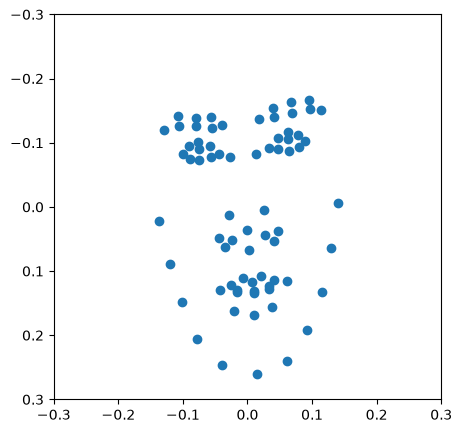

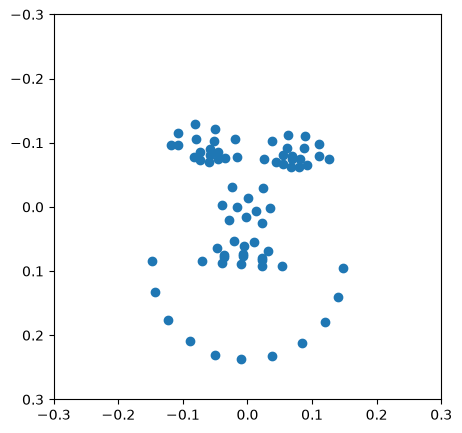

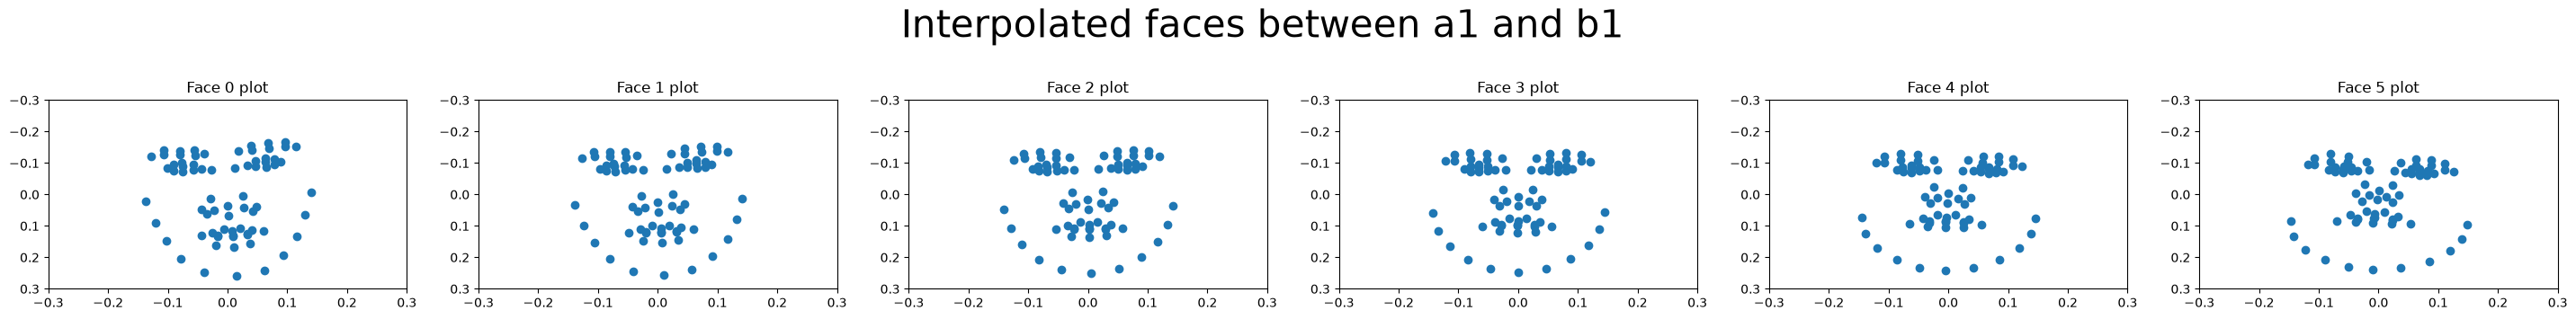

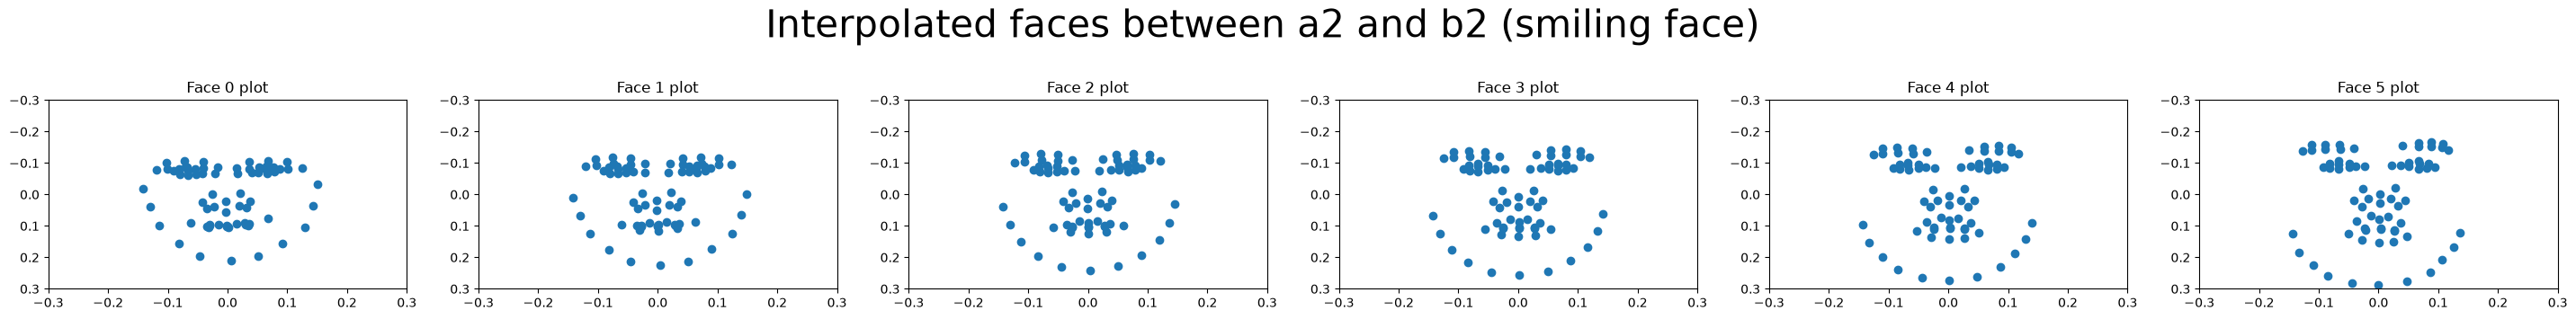

In [122]:
# TASK 7.1. Select points $\mathbf{a}$ and $\mathbf{b}$ in latent space (paying attention to the Gaussian constraints) and generate the faces.

a = np.array([-3*np.sqrt(val[0]), 0, -3*np.sqrt(val[2]), 0, 0])
b = np.array([3*np.sqrt(val[0]), 0, 3*np.sqrt(val[2]), 0, 0])

plot_face(transform_from_latent_space(a, used, mu))
plot_face(transform_from_latent_space(b, used, mu))

# TASK 7.2-3.

### FIRST ONE
a1 = np.array([-3*np.sqrt(val[0]), 0, -3*np.sqrt(val[2]), 0, 0])
b1 = np.array([3*np.sqrt(val[0]), 0, 3*np.sqrt(val[2]), 0, 0])
generated_faces_1 = []
for alpha in np.linspace(0, 1, num=6):
    interpolated_a = (1 - alpha) * a1 + alpha * b1
    generated_face = transform_from_latent_space(interpolated_a, used, mu)
    generated_faces_1.append(generated_face)

plot_many_faces(generated_faces_1, "Interpolated faces between a1 and b1")

### SECOND ONE
a2 = np.array([0, 5*np.sqrt(val[1]), 0, 0, 0])
b2 = np.array([0, -5*np.sqrt(val[1]), 0, 0, 0])
generated_faces_2 = []
for alpha in np.linspace(0, 1, num=6):
    interpolated_a = (1 - alpha) * a2 + alpha * b2
    generated_face = transform_from_latent_space(interpolated_a, used, mu)
    generated_faces_2.append(generated_face)   

plot_many_faces(generated_faces_2, "Interpolated faces between a2 and b2 (smiling face)")



## Task 8: Reflection


Describe and reflect on the results obtained from this assignment, the exercises and the in-class exercises. Answer the following questions:
1. **Behaviour:** Explain why, a set of points interpolated on a line in latent space corresponds to a sample on a line in data space using $x = \Phi\mathbf{a} + \mu$.
2. How well can a few principal components reproduce the samples? What happens with the generated data when the number of components $k$ is changed to 1,3,9, or 15?



</div></article>



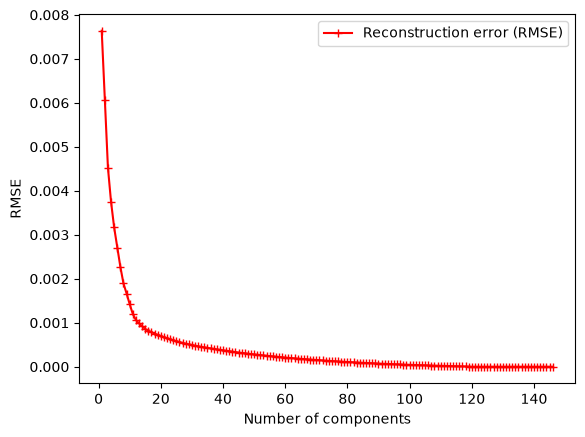

Reconstruction error with 1 components: 0.006069
Reconstruction error with 3 components: 0.003749
Reconstruction error with 9 components: 0.001421
Reconstruction error with 15 components: 0.000818


In [132]:
# TASK 8.1

### The mapping $$x = \Phi_{k} a + \mu$$ is an affine transformation (a linear transformation (the $$\Phi_k a$$) followed by a translation (the $$+ \mu$$)).
### Both of these operations preserve straight lines, meaning that if we take two points in the latent space and connect them with a straight line, the corresponding points in the original space will also be connected by a straight line. 
### Ergo, a straight line in latent space will map to a straight line in the original space, preserving the linearity of the transformation.

# TASK 8.2. 

def reconstruction_error(X, principal_components, mu):
    X_latent = transform_to_latent_space(X, principal_components, mu)
    X_reconstructed = transform_from_latent_space(X_latent, principal_components, mu)
    rmse = np.sqrt(np.mean((X - X_reconstructed) ** 2))
    return rmse

def reconstruction_error_plot(X, principal_components, mu):
    errs = []
    for i in range(len(principal_components)):
        errs.append(reconstruction_error(X, principal_components[:, :i], mu))

    x = np.arange(1, len(principal_components) + 1, 1)

    plt.figure()
    plt.xlabel('Number of components')
    plt.ylabel('RMSE')
    plt.plot(x, errs, 'r-+')
    plt.legend(['Reconstruction error (RMSE)'])
    plt.show()


reconstruction_error_plot(shapes, comp, mu)

for k in [1, 3, 9, 15]:
    error = reconstruction_error(shapes, comp[:, :k], mu)
    print(f"Reconstruction error with {k} components: {error.real:.6f}")


### There's two stories to tell:
### 1. The reconstruction error decreases as the number of components increases, which is expected since more components capture more variance in the data.
### 2. Given the results in TASK 3, to see that we capture much of the variance within the first 10 components, after that, it's diminshing returns.
### Ergo: Components go up -> reconstruction error goes down; Components go up -> variance captured goes up.
### however, the rate of improvement in reconstruction error decreases as the number of components increases, indicating that the first few components capture the most significant features of the data.

## Last section - optional (NOT DONE)
This final section includes three tasks that offer valuable insights into the application of PCA, however completing this section is optional.
<article class="message task"><a class="anchor" id="correlation_eigen"></a>
    <div class="message-header">
        <span>Task 9: Eigenvalues and eigenvectors of correlation matrix <em>(optional)</em></span>
        <span class="has-text-right"><i class="bi bi-code"></i>
          <i class="bi bi-lightbulb-fill"></i>
          <i class="bi bi-stoplights medium"></i>
            <i class="bi bi-exclamation-octagon-fill" style="color: #90EE90;"></i>
        </span>
    </div>
<div class="message-body">


1. Implement the function `get_principal_components_correlation`
 according to the comments in the cell below.
2. Use the provided code to display the eigenvalues of the correlation matrix.
3. How do the eigenvalues obtained from the covariance matrix compare to those from the correlation matrix in terms of magnitude and the variance each principal component explains? What does this reveal about the effect of feature scaling on PCA results?



</div></article>



In [0]:
def get_principal_components_correlation(X):
    """Calculates principal components using the correlation matrix for X.

    Args:
        X: The dataset. An NxD array where N are the number of samples and D are
        the number of features.

    Returns:
        Tuple (components, eigenvalues, mu) where components is a DxD matrix of
        principal components, eigenvalues is a D-element vector of
        corresponding eigenvalues, and mu is a D-element array containing the mean
        vector.
    """
    # Standardize the data
    
    # Compute the correlation matrix
    
    # Sort the eigenvalues and eigenvectors in descending order
    
    return ....

# Use the function on the shapes data
eigenvectors_corr, eigenvalues_corr, mu_corr = get_principal_components_correlation(shapes)

# Optionally, plot the eigenvalues to see their distribution
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(eigenvalues_corr) + 1), eigenvalues_corr, 'o-', linewidth=2)
plt.title('Eigenvalues of the Correlation Matrix')
plt.xlabel('Principal Component')
plt.ylabel('Eigenvalue')
plt.grid(True)
plt.show()

variance_explained = eigenvalues_corr / np.sum(eigenvalues_corr)
cumulative_variance_explained = np.cumsum(variance_explained)

# Plot cumulative variance explained
plt.figure(figsize=(8, 6))
plt.plot(range(1, len(cumulative_variance_explained) + 1),
         cumulative_variance_explained, 'o-', linewidth=2)
plt.title('Cumulative Variance Explained by Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance Explained')
plt.axhline(y=0.95, color='r', linestyle='--')  # Line to indicate 90% variance
plt.grid(True)
plt.show()

<article class="message task"><a class="anchor" id="Dimensionality_red"></a>
    <div class="message-header">
        <span>Task 10: Dimensionality reduction of features <em>(optional)</em></span>
        <span class="has-text-right"><i class="bi bi-code"></i>
          <i class="bi bi-lightbulb-fill"></i>
          <i class="bi bi-stoplights medium"></i>
            <i class="bi bi-exclamation-octagon-fill" style="color: #90EE90;"></i>
        </span>
    </div>
<div class="message-body">


1. **Transform data:** Use $\mathbf{\Phi^{\top}}$​ to transform the data $\mathbf{x}$ into its latent-space representation $\mathbf{x'}$ (using $\mathbf{x'}= \mathbf{\Phi^{\top}}(\mathbf{x}-\mathbf{\mu})$).
2. Plot the first two  components in latent space using a scatterplot.    - What does this plot tell you about the distribution of faces?
    - Try plotting different pairs of components. Describe how each combination separates (clusters) the dataset differently.


3. **Interpolate between real faces:** Re-implement [Task 6](#interpolate) but instead of selecting 2 points in latent space, transform two real faces to latent space and interpolate between them.    - Plot the faces of the interpolated points.





</div></article>



In [0]:
# Write implementation here

Describe the different scatter plots of component combinations
<article class="message task"><a class="anchor" id="Dimensionality_red"></a>
    <div class="message-header">
        <span>Task 11: Out of distribution generation <em>(optional)</em></span>
        <span class="has-text-right"><i class="bi bi-code"></i>
          <i class="bi bi-lightbulb-fill"></i>
          <i class="bi bi-stoplights medium"></i>
            <i class="bi bi-exclamation-octagon-fill" style="color: #90EE90;"></i>
        </span>
    </div>
<div class="message-body">


1. **Extreme values:** What happens if you select values outside the suggested range. Explain why this happens.



</div></article>



In [0]:
# Write implementation and reflections here